# 4 - Visualisations surprises

**Objectif** : Mettre en avant les résultats **surprenants** que les données révèlent — ceux que l'on n'attend pas.

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import seaborn as sns
import geopandas as gpd
import glob, sys, os, warnings
from pathlib import Path
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 130

# ── Chemins du projet ────────────────────────────────────────────────
PROJECT_ROOT = Path.cwd().parent
RAW_DIR      = PROJECT_ROOT / 'data' / 'raw'
FIGURES_DIR  = PROJECT_ROOT / 'figures'
FIGURES_DIR.mkdir(exist_ok=True)

# ── Constantes ───────────────────────────────────────────────────────
COLORS       = {'LOW': '#e07b54', 'MEDIUM': '#f0c05a', 'HIGH': '#4caf82'}
NIVEAUX      = ['LOW', 'MEDIUM', 'HIGH']
CODES        = ['EDU_AGGREGATE_BAS', 'EDU_AGGREGATE_INT', 'EDU_AGGREGATE_ADV']
CODES_NIVEAU = {'EDU_AGGREGATE_BAS': 'LOW', 'EDU_AGGREGATE_INT': 'MEDIUM', 'EDU_AGGREGATE_ADV': 'HIGH'}
ISCED_SUP    = ['EDU_ISCED11_5', 'EDU_ISCED11_6', 'EDU_ISCED11_7', 'EDU_ISCED11_8']
ISCED_LABELS = {
    'EDU_ISCED11_5': 'Bac+2\n(ISCED 5)',
    'EDU_ISCED11_6': 'Licence\n(ISCED 6)',
    'EDU_ISCED11_7': 'Master\n(ISCED 7)',
    'EDU_ISCED11_8': 'Doctorat\n(ISCED 8)',
}
COUNTRY_NAMES = {
    'CMR':'Cameroun',    'TUN':'Tunisie',     'SDN':'Soudan',
    'EGY':'Égypte',      'GIN':'Guinée',      'IND':'Inde',
    'SEN':'Sénégal',     'JOR':'Jordanie',    'BDI':'Burundi',
    'COD':'Congo RDC',   'IRN':'Iran',        'BGD':'Bangladesh',
    'POL':'Pologne',     'SVK':'Slovaquie',   'BGR':'Bulgarie',
    'CZE':'Tchéquie',   'MKD':'Macédoine',   'PSE':'Palestine',
    'AGO':'Angola',      'SWE':'Suède',       'ESP':'Espagne',
    'ROU':'Roumanie',    'GRC':'Grèce',       'IDN':'Indonésie',
    'LUX':'Luxembourg',  'KOS':'Kosovo',
}
REGIONS_ISCED = {
    'FRA':'Europe','DEU':'Europe','ITA':'Europe','ESP':'Europe','GBR':'Europe',
    'POL':'Europe','GRC':'Europe','PRT':'Europe','CZE':'Europe','HUN':'Europe',
    'SWE':'Europe','NOR':'Europe','DNK':'Europe','FIN':'Europe','AUT':'Europe',
    'USA':'Amériques','CAN':'Amériques','BRA':'Amériques','ARG':'Amériques',
    'COL':'Amériques','CHL':'Amériques','MEX':'Amériques','PER':'Amériques',
    'CHN':'Asie-Pacifique','JPN':'Asie-Pacifique','KOR':'Asie-Pacifique',
    'IND':'Asie-Pacifique','IDN':'Asie-Pacifique','AUS':'Asie-Pacifique',
    'ZAF':'Afrique','EGY':'Afrique','MAR':'Afrique','TUN':'Afrique',
    'SAU':'Moyen-Orient','TUR':'Moyen-Orient','IRN':'Moyen-Orient','JOR':'Moyen-Orient',
}

# ── Chargement des données brutes ────────────────────────────────────
emploi  = pd.read_csv(RAW_DIR / 'EMP_TEMP_SEX_EDU_NB_A.csv')
chomage = pd.read_csv(RAW_DIR / 'UNE_TUNE_SEX_EDU_NB_A.csv')

# ── Fonction principale de construction du dataset ───────────────────
def build(sex_filter, codes=None):
    """
    Construit le dataset fusionné emploi+chômage avec taux calculé.

    Paramètres
    ----------
    sex_filter : 'SEX_T' (total), 'SEX_F' (femmes), 'SEX_M' (hommes)
    codes      : liste de codes éducation ILO (CODES agrégés par défaut)

    Retourne
    --------
    DataFrame avec colonnes : ref_area, time, classif1, emp, une, taux, niveau
    """
    if codes is None:
        codes = CODES
    e = emploi[
        (emploi['sex'] == sex_filter) & (emploi['classif1'].isin(codes)) &
        emploi['obs_value'].notna() & (emploi['obs_status'] != 'U') &
        (emploi['time'] >= 2000) & (emploi['time'] <= 2023)
    ]
    u = chomage[
        (chomage['sex'] == sex_filter) & (chomage['classif1'].isin(codes)) &
        chomage['obs_value'].notna() & (chomage['obs_status'] != 'U') &
        (chomage['time'] >= 2000) & (chomage['time'] <= 2023)
    ]
    df = pd.merge(
        e[['ref_area','time','classif1','obs_value']].rename(columns={'obs_value':'emp'}),
        u[['ref_area','time','classif1','obs_value']].rename(columns={'obs_value':'une'}),
        on=['ref_area','time','classif1'], how='inner'
    )
    df['taux']   = df['une'] / (df['une'] + df['emp']) * 100
    df['niveau'] = df['classif1'].map(CODES_NIVEAU)
    return df

# ── Construction de tous les datasets nécessaires ────────────────────
df       = build('SEX_T')            # total
df_f     = build('SEX_F')            # femmes
df_m     = build('SEX_M')            # hommes
df_isced = build('SEX_T', ISCED_SUP) # niveaux universitaires détaillés
df_isced['region'] = df_isced['ref_area'].map(REGIONS_ISCED)

# ── Agrégations globales réutilisées dans plusieurs figures ──────────
taux_niv = df.groupby('niveau')['taux'].mean().reindex(NIVEAUX)
taux_f   = df_f.groupby('niveau')['taux'].mean().reindex(NIVEAUX)
taux_m   = df_m.groupby('niveau')['taux'].mean().reindex(NIVEAUX)
taux_sup = df_isced.groupby('classif1')['taux'].mean().reindex(ISCED_SUP)

# Écart LOW–HIGH par pays et par année (pour figures 14–16)
pivot_temps = (
    df.groupby(['ref_area','time','niveau'])['taux']
    .mean().unstack().reset_index()
)
pivot_temps.columns.name = None
pivot_temps['ecart'] = pivot_temps['LOW'] - pivot_temps['HIGH']

# Écart mondial moyen par année (pour figure 15)
ecart_mondial = df.groupby(['time','niveau'])['taux'].mean().unstack()
ecart_mondial['ecart'] = ecart_mondial['LOW'] - ecart_mondial['HIGH']

print('Données prêtes.')
print(f'  Total  : {df["ref_area"].nunique()} pays')
print(f'  Femmes : {df_f["ref_area"].nunique()} pays')
print(f'  Hommes : {df_m["ref_area"].nunique()} pays')
print(f'  Période : {df["time"].min()}–{df["time"].max()}')

Données prêtes.
  Total  : 175 pays
  Femmes : 174 pays
  Hommes : 174 pays
  Période : 2000–2023


---
## Figures 08 & 09 — Cartes choroplèthes mondiales

⚠️ **Nécessite `geopandas`** : `pip install geopandas` dans le terminal VS Code.

In [19]:
# Préparation des données pour les cartes
pivot_carte = df.groupby(['ref_area','niveau'])['taux'].mean().unstack().reset_index()
pivot_carte.columns.name = None
pivot_carte['ecart_low_high'] = pivot_carte['LOW'] - pivot_carte['HIGH']

# Chargement automatique du shapefile intégré à geopandas
shapefile_path = None
site_packages  = [p for p in sys.path if 'site-packages' in p or 'dist-packages' in p]
for sp in site_packages:
    matches = glob.glob(os.path.join(sp, '**', 'naturalearth_lowres.shp'), recursive=True)
    if matches:
        shapefile_path = matches[0]
        break

if shapefile_path:
    world = gpd.read_file(shapefile_path)
else:
    world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))

world_data = world.merge(
    pivot_carte[['ref_area','HIGH','ecart_low_high']],
    left_on='iso_a3', right_on='ref_area', how='left'
)
print(f'Pays avec données sur la carte : {world_data["HIGH"].notna().sum()} / {len(world_data)}')

Pays avec données sur la carte : 147 / 177


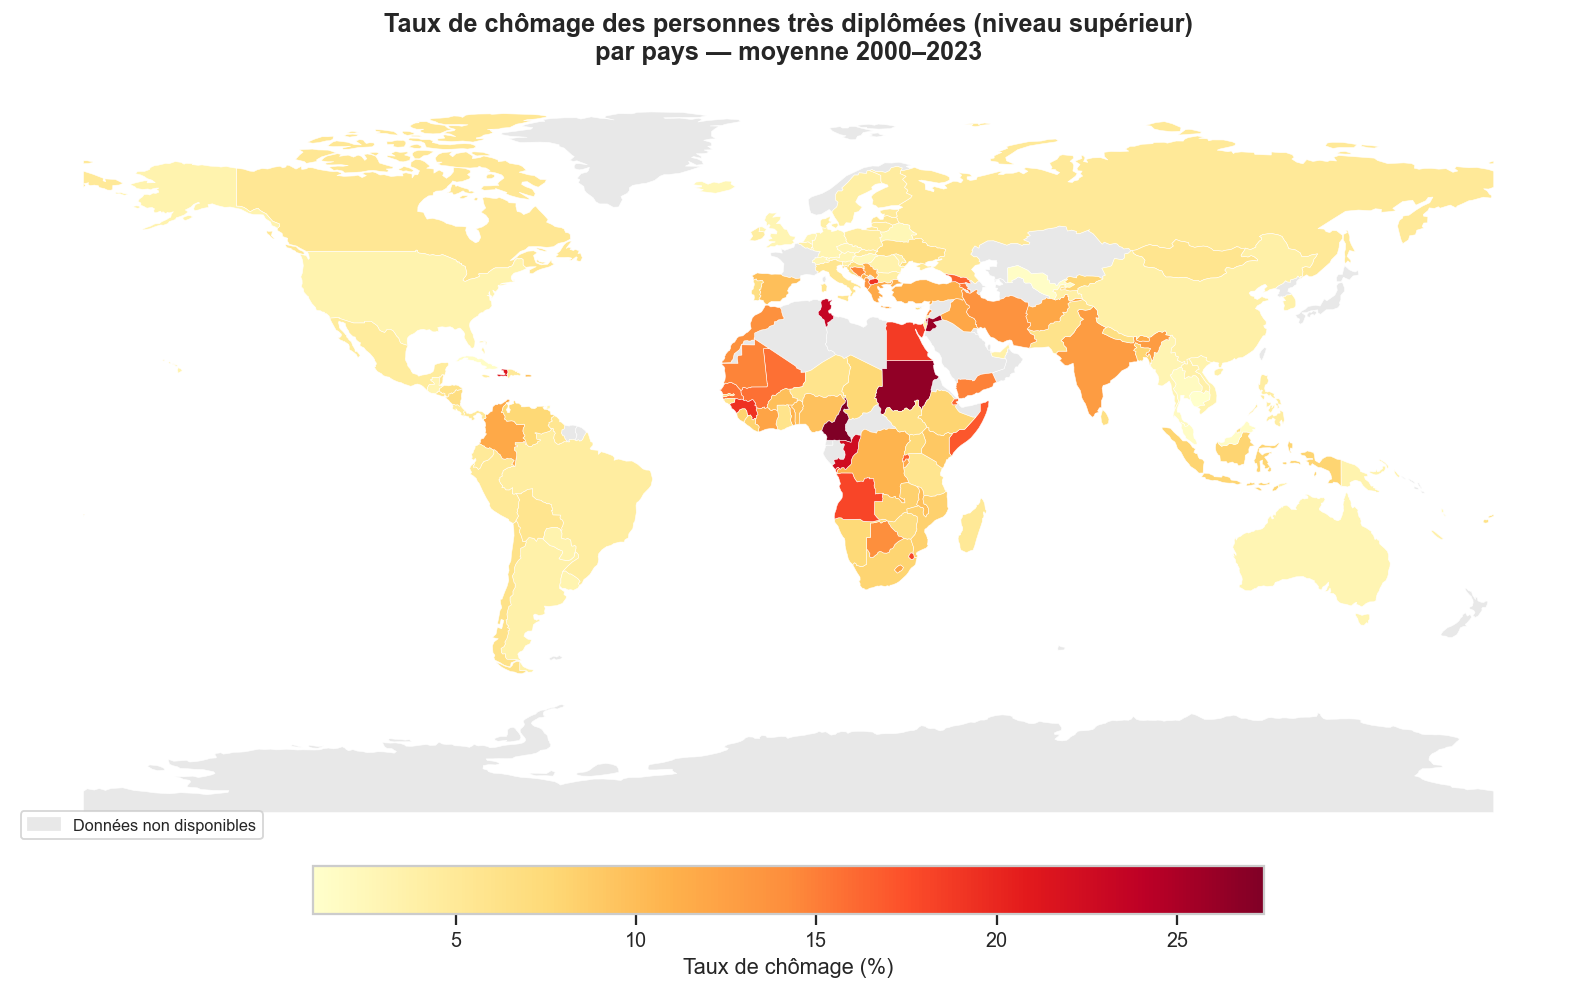

DESCRIPTION :
Carte mondiale : taux de chômage moyen des très diplômés par pays (2000–2023).

CE QU'ON EN DÉDUIT :
Même pour les très diplômés, le taux de chômage varie énormément selon les pays.


In [20]:
# ── Figure 08 : taux de chômage HIGH par pays ─────────────────────────
fig, ax = plt.subplots(1, 1, figsize=(15, 8))
world_data[world_data['HIGH'].isna()].plot(
    ax=ax, color='#e8e8e8', edgecolor='white', linewidth=0.3)
world_data[world_data['HIGH'].notna()].plot(
    column='HIGH', ax=ax, cmap='YlOrRd', edgecolor='white', linewidth=0.3,
    legend=True,
    legend_kwds={'label':'Taux de chômage (%)','shrink':0.5,
                 'orientation':'horizontal','pad':0.02})
ax.set_title('Taux de chômage des personnes très diplômées (niveau supérieur)\npar pays — moyenne 2000–2023',
             fontsize=14, fontweight='bold', pad=10)
ax.axis('off')
ax.legend(handles=[mpatches.Patch(color='#e8e8e8', label='Données non disponibles')],
          loc='lower left', fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '08_carte_taux_high.png', bbox_inches='tight')
plt.show()

print('DESCRIPTION :')
print('Carte mondiale : taux de chômage moyen des très diplômés par pays (2000–2023).')
print()
print('CE QU\'ON EN DÉDUIT :')
print('Même pour les très diplômés, le taux de chômage varie énormément selon les pays.')

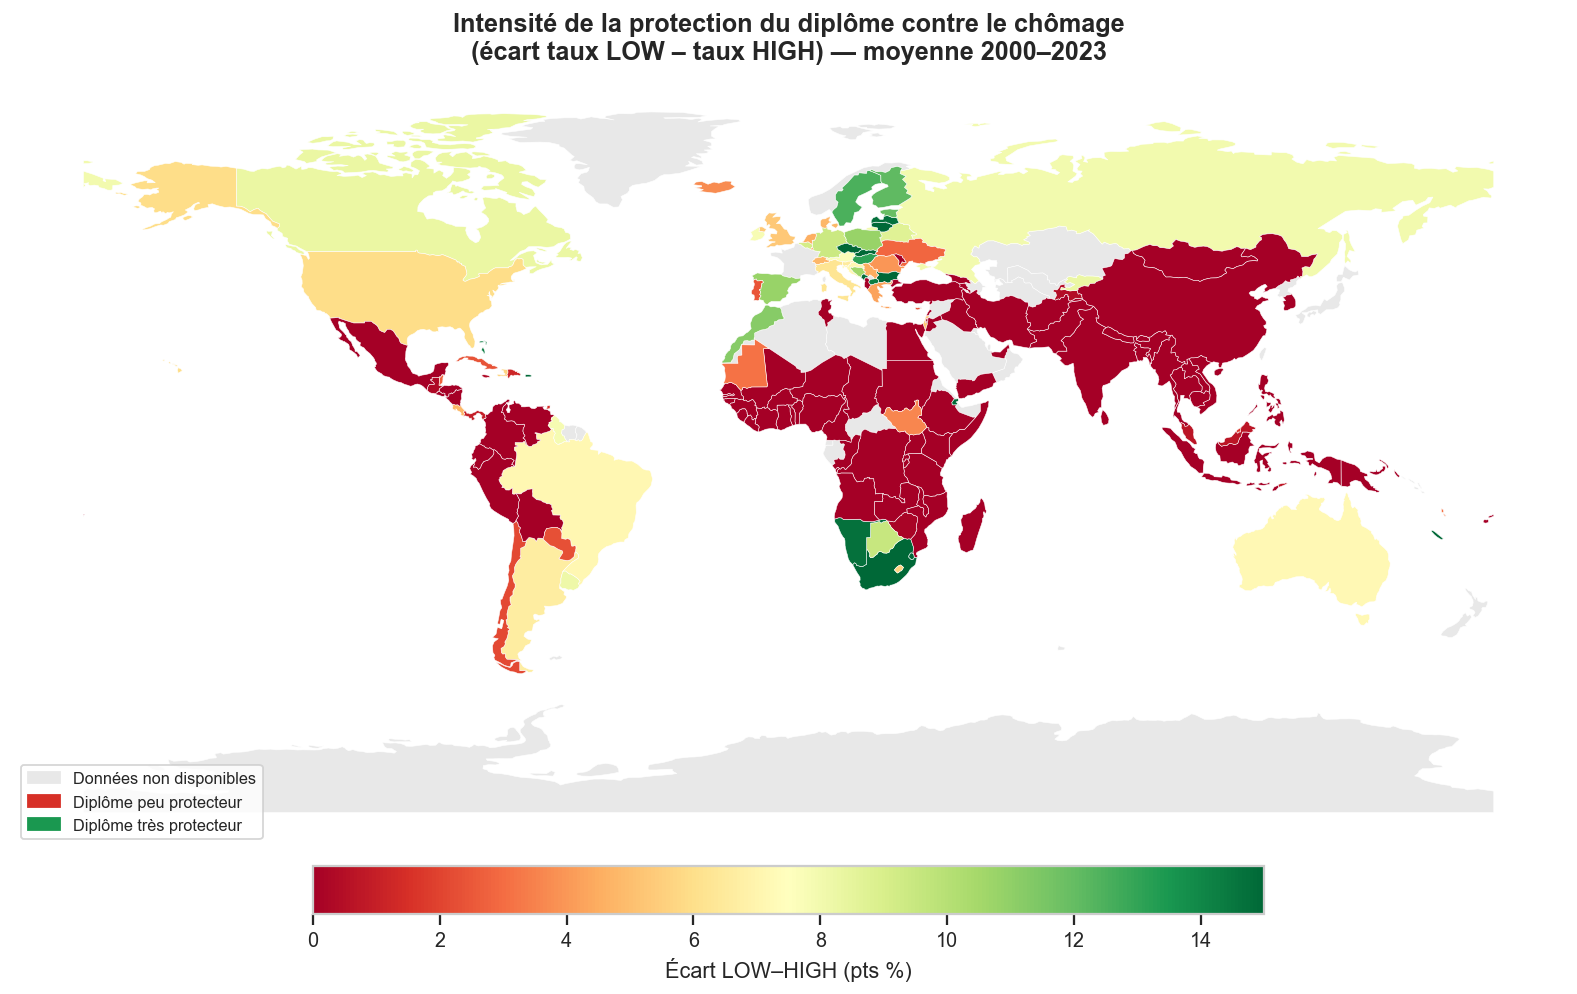

DESCRIPTION :
Pour chaque pays : écart entre taux de chômage LOW et HIGH.

CE QU'ON EN DÉDUIT :
La protection du diplôme est loin d'être uniforme — certains pays affichent
même un écart négatif, où les diplômés chôment plus que les peu diplômés.


In [21]:
# ── Figure 09 : écart LOW–HIGH par pays ───────────────────────────────
fig, ax = plt.subplots(1, 1, figsize=(15, 8))
world_data[world_data['ecart_low_high'].isna()].plot(
    ax=ax, color='#e8e8e8', edgecolor='white', linewidth=0.3)
world_data[world_data['ecart_low_high'].notna()].plot(
    column='ecart_low_high', ax=ax, cmap='RdYlGn',
    edgecolor='white', linewidth=0.3, vmin=0, vmax=15,
    legend=True,
    legend_kwds={'label':'Écart LOW–HIGH (pts %)','shrink':0.5,
                 'orientation':'horizontal','pad':0.02})
ax.set_title('Intensité de la protection du diplôme contre le chômage\n'
             '(écart taux LOW – taux HIGH) — moyenne 2000–2023',
             fontsize=14, fontweight='bold', pad=10)
ax.axis('off')
ax.legend(handles=[
    mpatches.Patch(color='#e8e8e8', label='Données non disponibles'),
    mpatches.Patch(color='#d73027', label='Diplôme peu protecteur'),
    mpatches.Patch(color='#1a9850', label='Diplôme très protecteur'),
], loc='lower left', fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '09_carte_ecart_protection.png', bbox_inches='tight')
plt.show()

print('DESCRIPTION :')
print('Pour chaque pays : écart entre taux de chômage LOW et HIGH.')
print()
print('CE QU\'ON EN DÉDUIT :')
print('La protection du diplôme est loin d\'être uniforme — certains pays affichent')
print('même un écart négatif, où les diplômés chôment plus que les peu diplômés.')

---
## Figure 10 — Synthèse générale (3 panneaux)

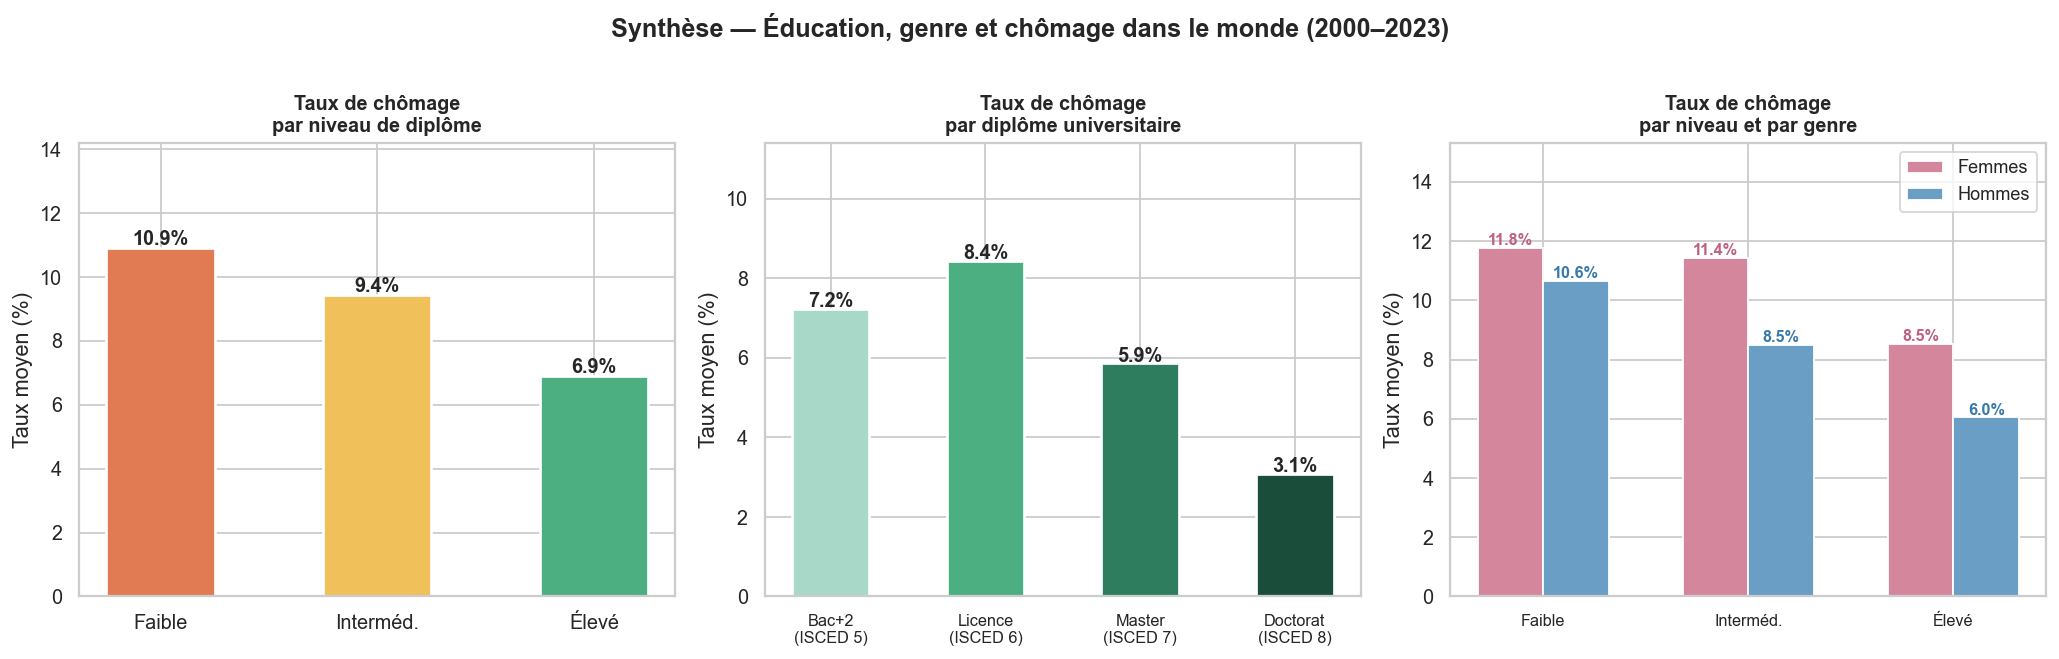

Figure 10 sauvegardée.


In [22]:
couleurs_sup = ['#a8d8c8', '#4caf82', '#2e7d5e', '#1a4d3a']
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Panneau 1 : taux par niveau
ax = axes[0]
bars = ax.bar(['Faible', 'Interméd.', 'Élevé'], taux_niv.values,
              color=[COLORS[k] for k in NIVEAUX], edgecolor='white', linewidth=1.5, width=0.5)
for b, v in zip(bars, taux_niv.values):
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.1,
            f'{v:.1f}%', ha='center', fontweight='bold', fontsize=11)
ax.set_title('Taux de chômage\npar niveau de diplôme', fontweight='bold', fontsize=11)
ax.set_ylabel('Taux moyen (%)'); ax.set_ylim(0, taux_niv.max()*1.3)

# Panneau 2 : ISCED 5–8
ax = axes[1]
bars = ax.bar([ISCED_LABELS[c] for c in ISCED_SUP], taux_sup.values,
              color=couleurs_sup, edgecolor='white', linewidth=1.5, width=0.5)
for b, v in zip(bars, taux_sup.values):
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.05,
            f'{v:.1f}%', ha='center', fontweight='bold', fontsize=11)
ax.set_title('Taux de chômage\npar diplôme universitaire', fontweight='bold', fontsize=11)
ax.set_ylabel('Taux moyen (%)'); ax.set_ylim(0, taux_sup.max()*1.35)
ax.tick_params(axis='x', labelsize=9)

# Panneau 3 : genre
ax = axes[2]
x = np.arange(3); w = 0.32
bars_f = ax.bar(x-w/2, taux_f.values, w, label='Femmes', color='#d4869c', edgecolor='white')
bars_m = ax.bar(x+w/2, taux_m.values, w, label='Hommes', color='#6a9ec5', edgecolor='white')
for b, v in zip(bars_f, taux_f.values):
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.1,
            f'{v:.1f}%', ha='center', fontsize=9, color='#c06080', fontweight='bold')
for b, v in zip(bars_m, taux_m.values):
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.1,
            f'{v:.1f}%', ha='center', fontsize=9, color='#3a7aaa', fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(['Faible','Interméd.','Élevé'], fontsize=9)
ax.set_title('Taux de chômage\npar niveau et par genre', fontweight='bold', fontsize=11)
ax.set_ylabel('Taux moyen (%)'); ax.legend(fontsize=10)
ax.set_ylim(0, max(taux_f.max(), taux_m.max())*1.3)

plt.suptitle('Synthèse — Éducation, genre et chômage dans le monde (2000–2023)',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '10_synthese.png', bbox_inches='tight')
plt.show()
print('Figure 10 sauvegardée.')

---
## Figure 11 — Le paradoxe du chômage éduqué

Dans **45% des pays analysés**, les très diplômés ont un taux de chômage plus élevé que les peu diplômés.

Pays paradoxaux : 75 / 165 = 45%


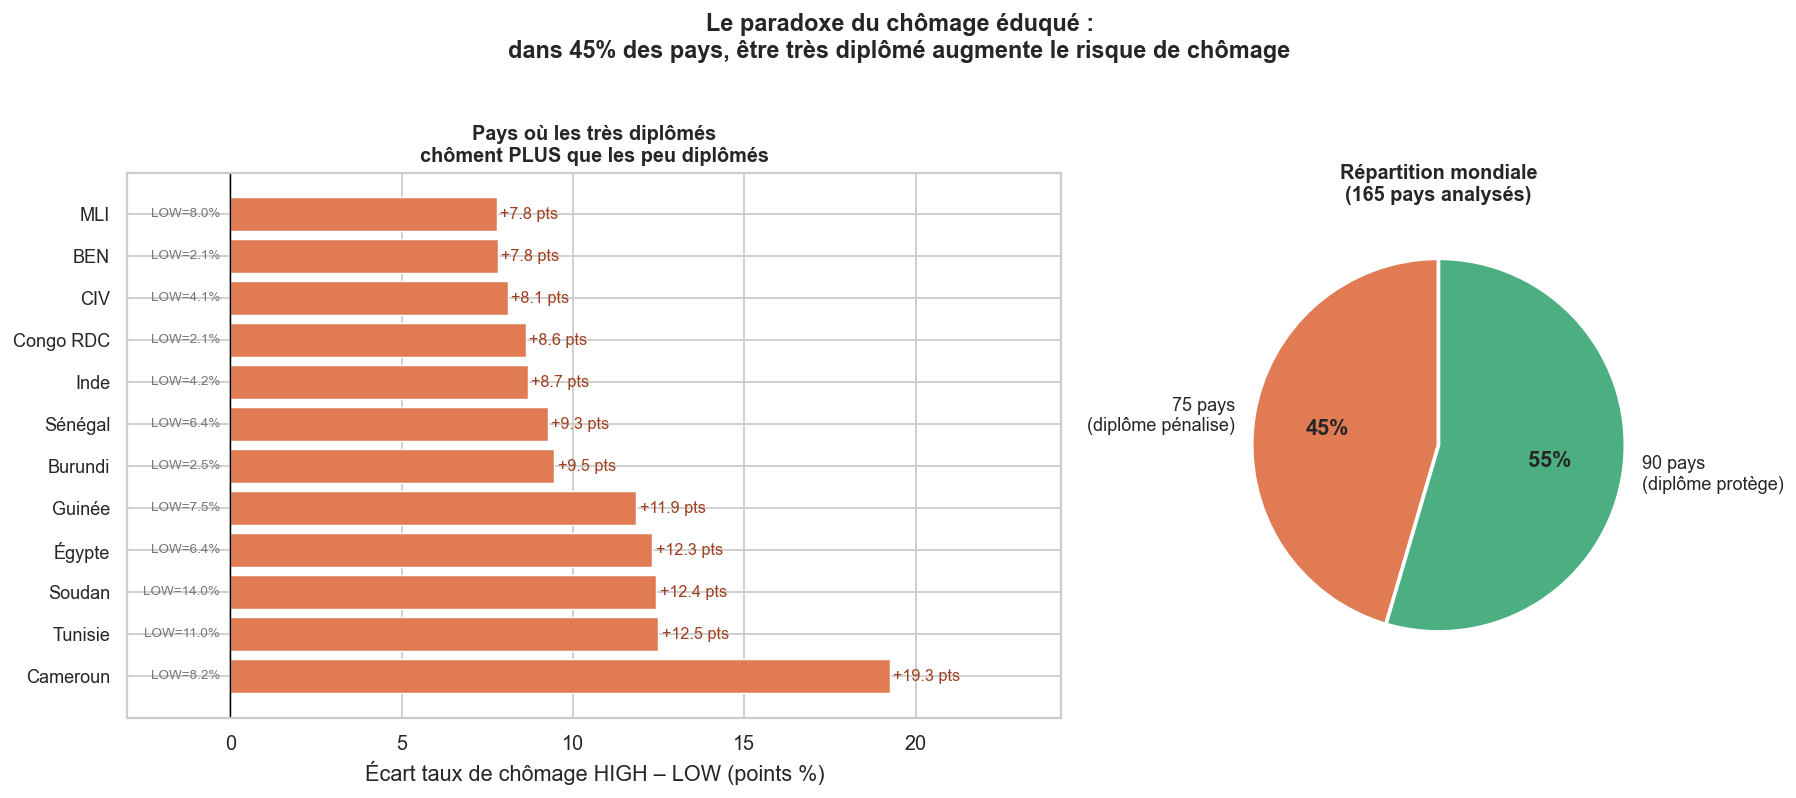

DESCRIPTION :
Dans 75 pays sur 165, les très diplômés chôment davantage que les peu diplômés.

CE QU'ON EN DÉDUIT :
Quand le marché du travail formel est trop petit (pays en développement),
les peu diplômés s'insèrent dans l'emploi informel tandis que les diplômés
attendent un poste qualifié qui n'existe pas en nombre suffisant.


In [23]:
pivot_paradox = df.groupby(['ref_area','niveau'])['taux'].mean().unstack().dropna()
pivot_paradox['ecart'] = pivot_paradox['HIGH'] - pivot_paradox['LOW']
paradox   = pivot_paradox[pivot_paradox['ecart'] > 0].sort_values('ecart', ascending=False).head(12)
n_paradox = (pivot_paradox['ecart'] > 0).sum()
n_total   = len(pivot_paradox)

print(f'Pays paradoxaux : {n_paradox} / {n_total} = {n_paradox/n_total*100:.0f}%')

fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={'width_ratios': [2, 1]})

ax = axes[0]
pays_labels = [COUNTRY_NAMES.get(c, c) for c in paradox.index]
y_pos = np.arange(len(paradox))
ax.barh(y_pos, paradox['ecart'].values, color='#e07b54', edgecolor='white', linewidth=0.8)
ax.set_yticks(y_pos); ax.set_yticklabels(pays_labels, fontsize=10)
ax.set_xlabel('Écart taux de chômage HIGH – LOW (points %)')
ax.set_title('Pays où les très diplômés\nchôment PLUS que les peu diplômés',
             fontweight='bold', fontsize=11)
ax.axvline(0, color='black', linewidth=0.8)
for i, v in enumerate(paradox['ecart'].values):
    ax.text(v+0.1, i, f'+{v:.1f} pts', va='center', fontsize=9, color='#a04020')
for i, (_, row) in enumerate(paradox.iterrows()):
    ax.text(-0.3, i, f'LOW={row["LOW"]:.1f}%', va='center', ha='right', fontsize=7.5, color='#777')
ax.set_xlim(-3, paradox['ecart'].max()+5)

ax2 = axes[1]
wedges, texts, autotexts = ax2.pie(
    [n_paradox, n_total - n_paradox],
    labels=[f'{n_paradox} pays\n(diplôme pénalise)', f'{n_total-n_paradox} pays\n(diplôme protège)'],
    colors=['#e07b54','#4caf82'], autopct='%1.0f%%', startangle=90,
    wedgeprops={'edgecolor':'white','linewidth':2}, textprops={'fontsize':10}
)
for at in autotexts:
    at.set_fontweight('bold'); at.set_fontsize(12)
ax2.set_title(f'Répartition mondiale\n({n_total} pays analysés)', fontweight='bold', fontsize=11)

plt.suptitle(
    f'Le paradoxe du chômage éduqué :\n'
    f'dans {n_paradox/n_total*100:.0f}% des pays, être très diplômé augmente le risque de chômage',
    fontsize=13, fontweight='bold', y=1.02
)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '11_paradoxe_chomage_eduque.png', bbox_inches='tight')
plt.show()

print('DESCRIPTION :')
print(f'Dans {n_paradox} pays sur {n_total}, les très diplômés chôment davantage que les peu diplômés.')
print()
print('CE QU\'ON EN DÉDUIT :')
print('Quand le marché du travail formel est trop petit (pays en développement),')
print('les peu diplômés s\'insèrent dans l\'emploi informel tandis que les diplômés')
print('attendent un poste qualifié qui n\'existe pas en nombre suffisant.')

---
## Figure 12 — COVID vs crise 2008 : les diplômés n'ont pas souffert pareil

En 2008 : hausse relative +17% pour les HIGH. En 2020 : seulement +2.2%. Le **télétravail** a tout changé.

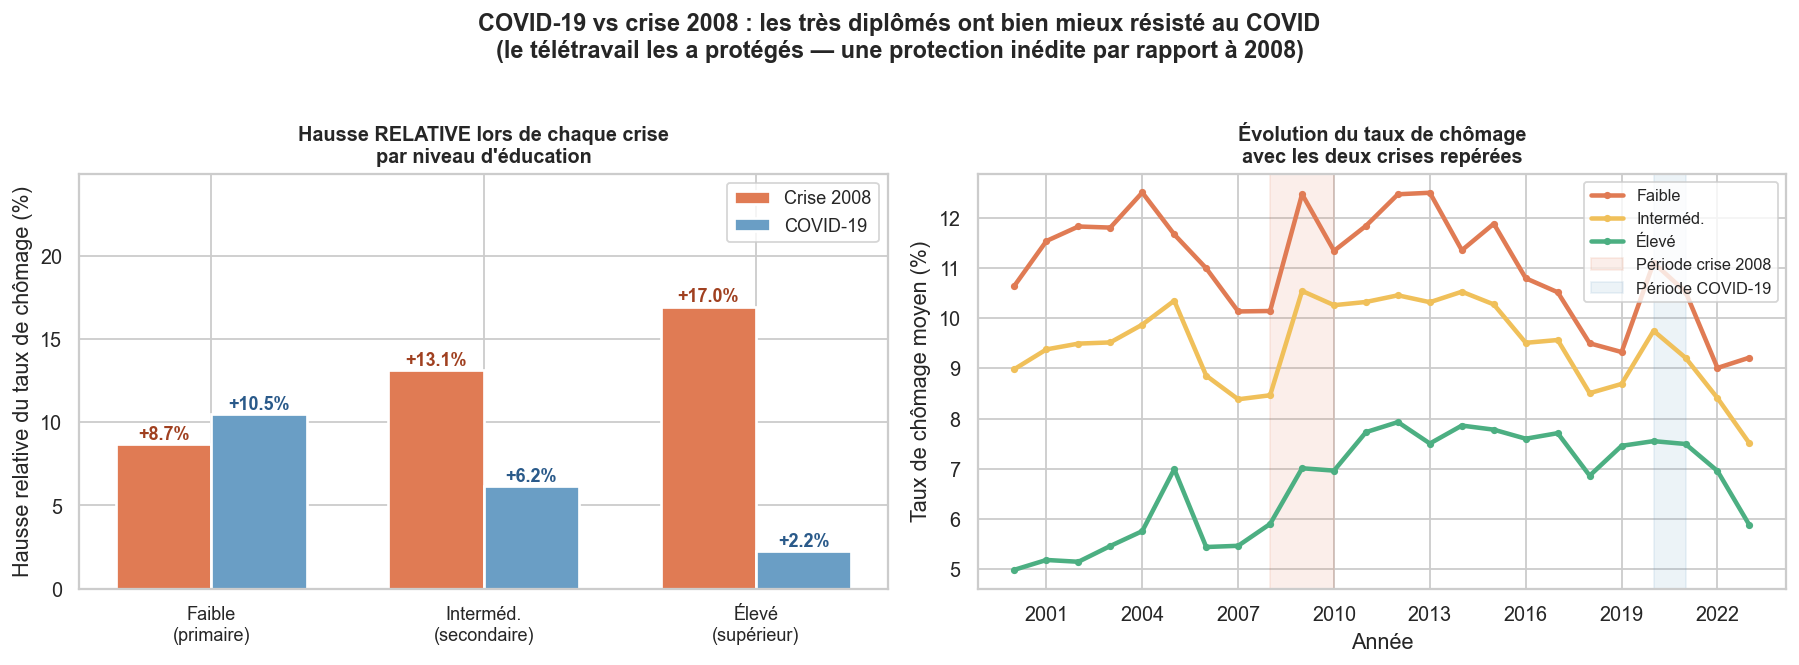

DESCRIPTION :
Comparaison de l'impact des deux grandes crises sur le taux de chômage par niveau.

CE QU'ON EN DÉDUIT :
En 2008 : les HIGH ont subi la hausse relative la plus forte (+17%).
En 2020 : les HIGH ont été presque épargnés (+2.2%) grâce au télétravail.


In [24]:
avant_2008  = df[(df['time']>=2005)&(df['time']<=2007)].groupby('niveau')['taux'].mean().reindex(NIVEAUX)
pic_2008    = df[(df['time']>=2009)&(df['time']<=2010)].groupby('niveau')['taux'].mean().reindex(NIVEAUX)
avant_covid = df[(df['time']>=2017)&(df['time']<=2019)].groupby('niveau')['taux'].mean().reindex(NIVEAUX)
pic_covid   = df[(df['time']>=2020)&(df['time']<=2021)].groupby('niveau')['taux'].mean().reindex(NIVEAUX)

hausse_2008  = ((pic_2008  - avant_2008)  / avant_2008  * 100).reindex(NIVEAUX)
hausse_covid = ((pic_covid - avant_covid) / avant_covid * 100).reindex(NIVEAUX)
taux_time    = df.groupby(['time','niveau'])['taux'].mean().reset_index()

x_labels = ['Faible\n(primaire)', 'Interméd.\n(secondaire)', 'Élevé\n(supérieur)']
x = np.arange(3); w = 0.35

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
bars1 = ax.bar(x-w/2, hausse_2008.values,  w, label='Crise 2008',
               color='#e07b54', edgecolor='white', linewidth=1.5)
bars2 = ax.bar(x+w/2, hausse_covid.values, w, label='COVID-19',
               color='#6a9ec5', edgecolor='white', linewidth=1.5)
for b, v in zip(bars1, hausse_2008.values):
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.3,
            f'{v:+.1f}%', ha='center', fontsize=10, fontweight='bold', color='#a04020')
for b, v in zip(bars2, hausse_covid.values):
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.3,
            f'{v:+.1f}%', ha='center', fontsize=10, fontweight='bold', color='#2a5a8a')
ax.set_xticks(x); ax.set_xticklabels(x_labels, fontsize=10)
ax.set_ylabel('Hausse relative du taux de chômage (%)')
ax.set_title('Hausse RELATIVE lors de chaque crise\npar niveau d\'éducation', fontweight='bold', fontsize=11)
ax.legend(fontsize=10); ax.axhline(0, color='black', linewidth=0.5)
ax.set_ylim(min(hausse_covid.min()-2, 0), hausse_2008.max()+8)

ax2 = axes[1]
for niv in NIVEAUX:
    sub = taux_time[taux_time['niveau']==niv]
    ax2.plot(sub['time'], sub['taux'],
             label={'LOW':'Faible','MEDIUM':'Interméd.','HIGH':'Élevé'}[niv],
             color=COLORS[niv], linewidth=2.5, marker='o', markersize=3)
ax2.axvspan(2008, 2010, alpha=0.12, color='#e07b54', label='Période crise 2008')
ax2.axvspan(2020, 2021, alpha=0.12, color='#6a9ec5', label='Période COVID-19')
ax2.set_title('Évolution du taux de chômage\navec les deux crises repérées', fontweight='bold', fontsize=11)
ax2.set_xlabel('Année'); ax2.set_ylabel('Taux de chômage moyen (%)')
ax2.legend(fontsize=9); ax2.xaxis.set_major_locator(mticker.MultipleLocator(3))

plt.suptitle(
    'COVID-19 vs crise 2008 : les très diplômés ont bien mieux résisté au COVID\n'
    '(le télétravail les a protégés — une protection inédite par rapport à 2008)',
    fontsize=13, fontweight='bold', y=1.02
)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '12_2008_vs_covid.png', bbox_inches='tight')
plt.show()

print('DESCRIPTION :')
print('Comparaison de l\'impact des deux grandes crises sur le taux de chômage par niveau.')
print()
print('CE QU\'ON EN DÉDUIT :')
print('En 2008 : les HIGH ont subi la hausse relative la plus forte (+17%).')
print('En 2020 : les HIGH ont été presque épargnés (+2.2%) grâce au télétravail.')

---
## Figure 13 — En Europe, la Licence donne plus de chômage que le Bac+2

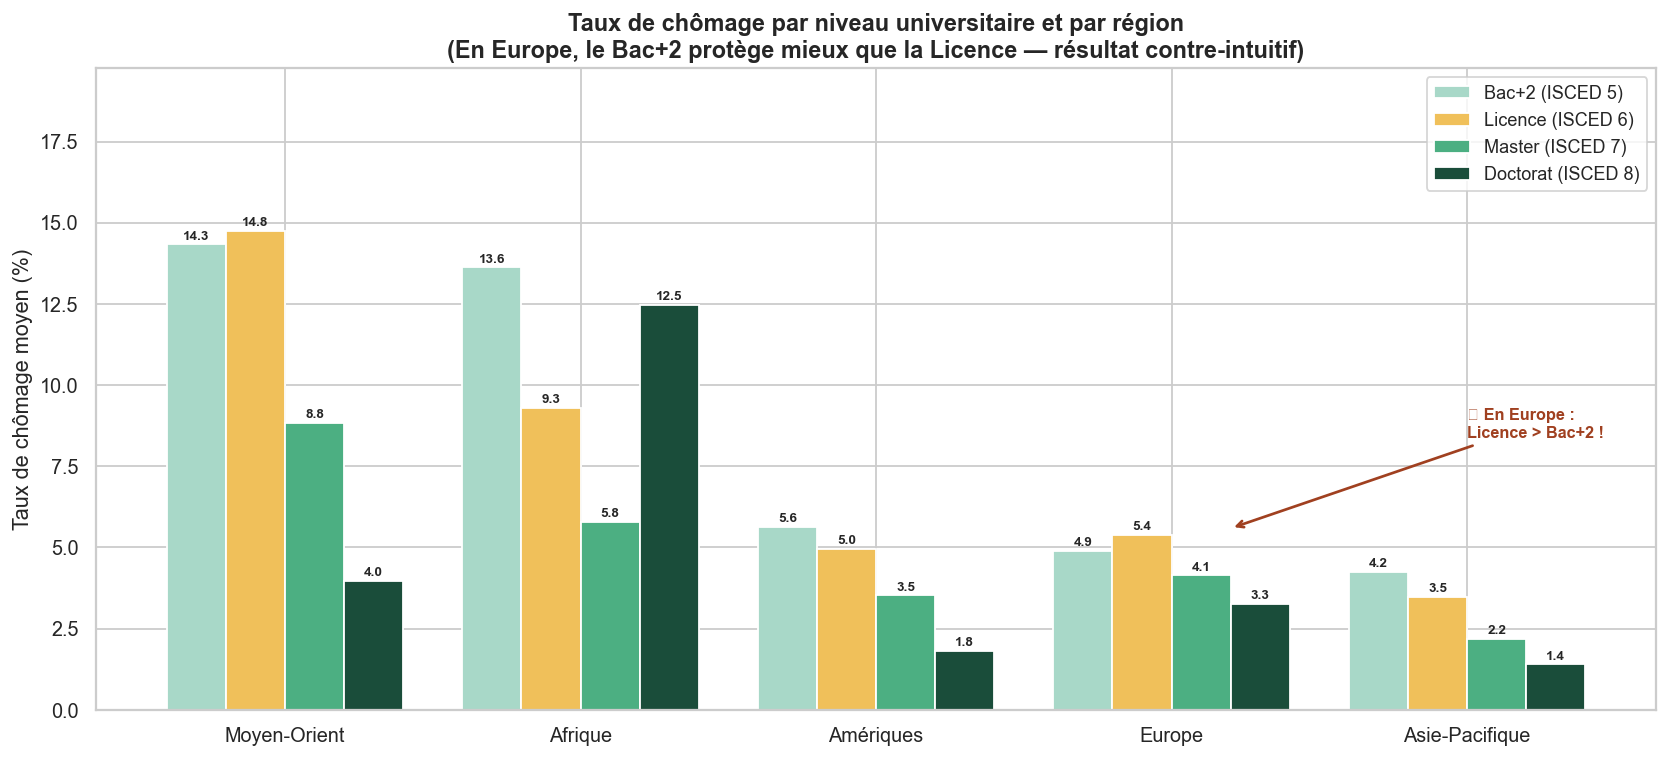

DESCRIPTION :
Taux de chômage par niveau universitaire (ISCED 5 à 8) selon la région du monde.

CE QU'ON EN DÉDUIT :
En Europe, la Licence affiche un taux plus élevé que le Bac+2 — les formations
courtes professionnalisantes (BTS, DUT, apprentissage) débouchent directement
sur l'emploi contrairement à la Licence, souvent tremplin vers le Master.


In [25]:
taux_reg_isced = (
    df_isced[df_isced['region'].notna()]
    .groupby(['region','classif1'])['taux']
    .mean().unstack()
    .reindex(columns=ISCED_SUP)
)
taux_reg_isced.columns = ['Bac+2\n(ISCED 5)','Licence\n(ISCED 6)','Master\n(ISCED 7)','Doctorat\n(ISCED 8)']
taux_reg_isced = taux_reg_isced.sort_values('Bac+2\n(ISCED 5)', ascending=False)

fig, ax = plt.subplots(figsize=(13, 6))
x = np.arange(len(taux_reg_isced)); w = 0.2
cols_isced   = ['#a8d8c8','#f0c05a','#4caf82','#1a4d3a']
labels_isced = ['Bac+2 (ISCED 5)','Licence (ISCED 6)','Master (ISCED 7)','Doctorat (ISCED 8)']

for i, (col_name, color, label) in enumerate(zip(taux_reg_isced.columns, cols_isced, labels_isced)):
    offsets = x + (i - 1.5) * w
    bars = ax.bar(offsets, taux_reg_isced[col_name].values, w,
                  label=label, color=color, edgecolor='white', linewidth=1)
    for b, v in zip(bars, taux_reg_isced[col_name].values):
        if not np.isnan(v):
            ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.15,
                    f'{v:.1f}', ha='center', fontsize=7.5, fontweight='bold')

europe_idx = list(taux_reg_isced.index).index('Europe')
lic_val    = taux_reg_isced.loc['Europe','Licence\n(ISCED 6)']
ax.annotate('⚠ En Europe :\nLicence > Bac+2 !',
            xy=(europe_idx + 0.2, lic_val + 0.2),
            xytext=(europe_idx + 1.0, lic_val + 3),
            fontsize=9, color='#a04020', fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='#a04020', lw=1.5))

ax.set_xticks(x); ax.set_xticklabels(taux_reg_isced.index, fontsize=11)
ax.set_ylabel('Taux de chômage moyen (%)')
ax.set_title('Taux de chômage par niveau universitaire et par région\n'
             '(En Europe, le Bac+2 protège mieux que la Licence — résultat contre-intuitif)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=10, loc='upper right')
ax.set_ylim(0, taux_reg_isced.max().max() + 5)

plt.tight_layout()
plt.savefig(FIGURES_DIR / '13_paradoxe_licence_europe.png', bbox_inches='tight')
plt.show()

print('DESCRIPTION :')
print('Taux de chômage par niveau universitaire (ISCED 5 à 8) selon la région du monde.')
print()
print('CE QU\'ON EN DÉDUIT :')
print('En Europe, la Licence affiche un taux plus élevé que le Bac+2 — les formations')
print('courtes professionnalisantes (BTS, DUT, apprentissage) débouchent directement')
print('sur l\'emploi contrairement à la Licence, souvent tremplin vers le Master.')

---
## Figure 14 — Le chômage éduqué s'aggrave : de 25 à 67 pays en 20 ans

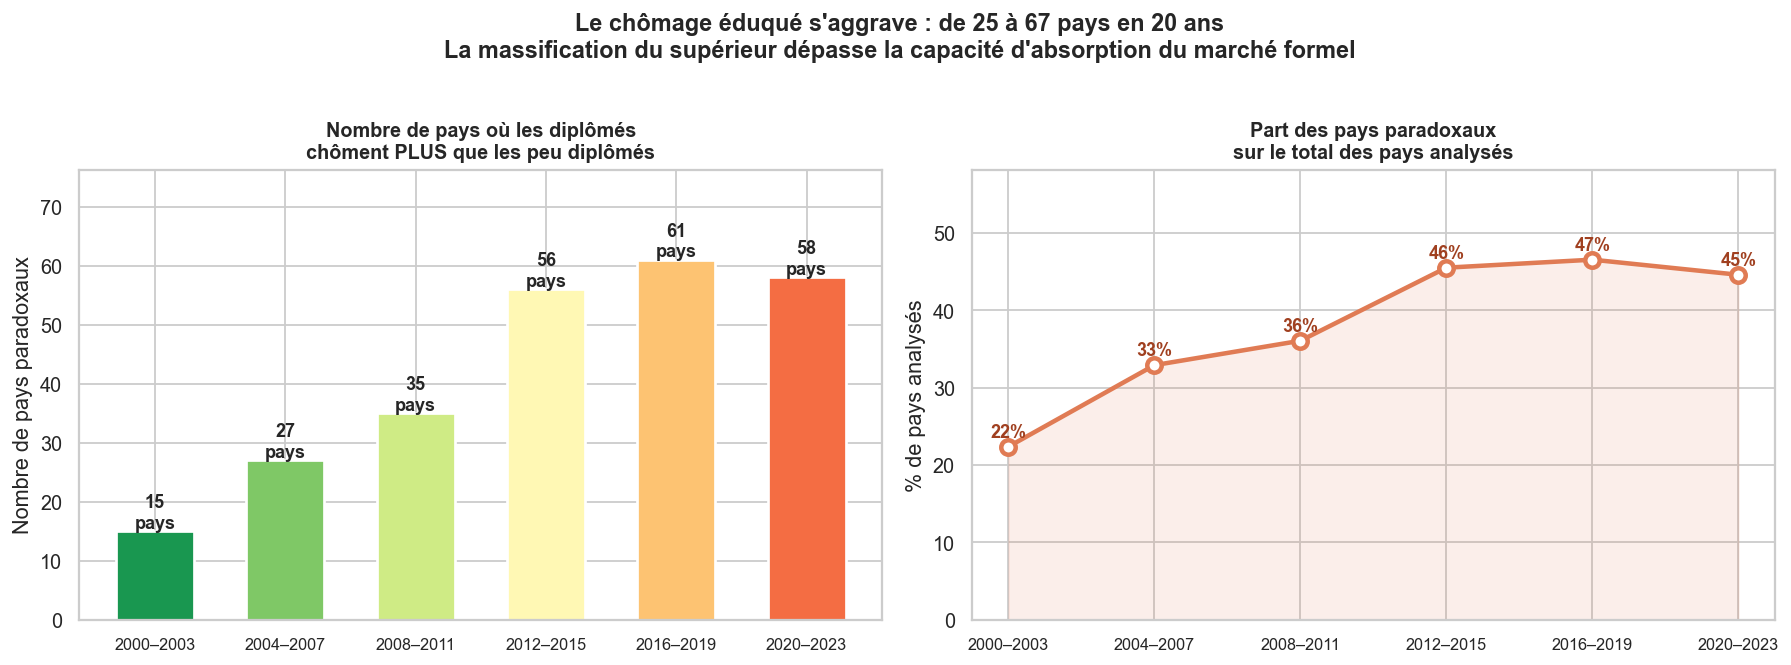

DESCRIPTION :
Évolution du nombre de pays paradoxaux sur 6 périodes de 4 ans.

CE QU'ON EN DÉDUIT :
De 15 pays (22%) à 58 pays (45%) en 20 ans.
Le phénomène s'amplifie — ce n'est pas une anomalie passagère.


In [26]:
periodes = [
    ('2000–2003', 2000, 2003), ('2004–2007', 2004, 2007),
    ('2008–2011', 2008, 2011), ('2012–2015', 2012, 2015),
    ('2016–2019', 2016, 2019), ('2020–2023', 2020, 2023),
]
resultats = []
for label, debut, fin in periodes:
    sub = df[(df['time'] >= debut) & (df['time'] <= fin)]
    piv = sub.groupby(['ref_area','niveau'])['taux'].mean().unstack().dropna()
    n_p = (piv['HIGH'] > piv['LOW']).sum()
    n_t = len(piv)
    resultats.append({'periode': label, 'n_paradox': n_p, 'n_total': n_t, 'pct': n_p/n_t*100})
res = pd.DataFrame(resultats)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
bar_colors = plt.cm.RdYlGn_r(np.linspace(0.1, 0.8, len(res)))
bars = ax.bar(res['periode'], res['n_paradox'], color=bar_colors,
              edgecolor='white', linewidth=1.5, width=0.6)
for b, row in zip(bars, res.itertuples()):
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.5,
            f'{row.n_paradox}\npays', ha='center', fontsize=10, fontweight='bold')
ax.set_ylabel('Nombre de pays paradoxaux')
ax.set_title('Nombre de pays où les diplômés\nchôment PLUS que les peu diplômés',
             fontweight='bold', fontsize=11)
ax.set_ylim(0, res['n_paradox'].max() * 1.25)
ax.tick_params(axis='x', labelsize=9)

ax2 = axes[1]
ax2.plot(res['periode'], res['pct'], color='#e07b54',
         linewidth=2.5, marker='o', markersize=8,
         markerfacecolor='white', markeredgewidth=2.5)
for i, row in res.iterrows():
    ax2.text(i, row['pct']+1.2, f"{row['pct']:.0f}%",
             ha='center', fontsize=10, fontweight='bold', color='#a04020')
ax2.fill_between(range(len(res)), res['pct'], alpha=0.12, color='#e07b54')
ax2.set_xticks(range(len(res))); ax2.set_xticklabels(res['periode'], fontsize=9)
ax2.set_ylabel('% de pays analysés')
ax2.set_title('Part des pays paradoxaux\nsur le total des pays analysés',
              fontweight='bold', fontsize=11)
ax2.set_ylim(0, res['pct'].max() * 1.25)

plt.suptitle(
    'Le chômage éduqué s\'aggrave : de 25 à 67 pays en 20 ans\n'
    'La massification du supérieur dépasse la capacité d\'absorption du marché formel',
    fontsize=13, fontweight='bold', y=1.02
)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '14_chomage_eduque_aggravation.png', bbox_inches='tight')
plt.show()

print('DESCRIPTION :')
print('Évolution du nombre de pays paradoxaux sur 6 périodes de 4 ans.')
print()
print('CE QU\'ON EN DÉDUIT :')
print(f'De {res.iloc[0]["n_paradox"]} pays ({res.iloc[0]["pct"]:.0f}%) à {res.iloc[-1]["n_paradox"]} pays ({res.iloc[-1]["pct"]:.0f}%) en 20 ans.')
print('Le phénomène s\'amplifie — ce n\'est pas une anomalie passagère.')

---
## Figure 15 — L'avantage du diplôme se réduit de moitié en 20 ans

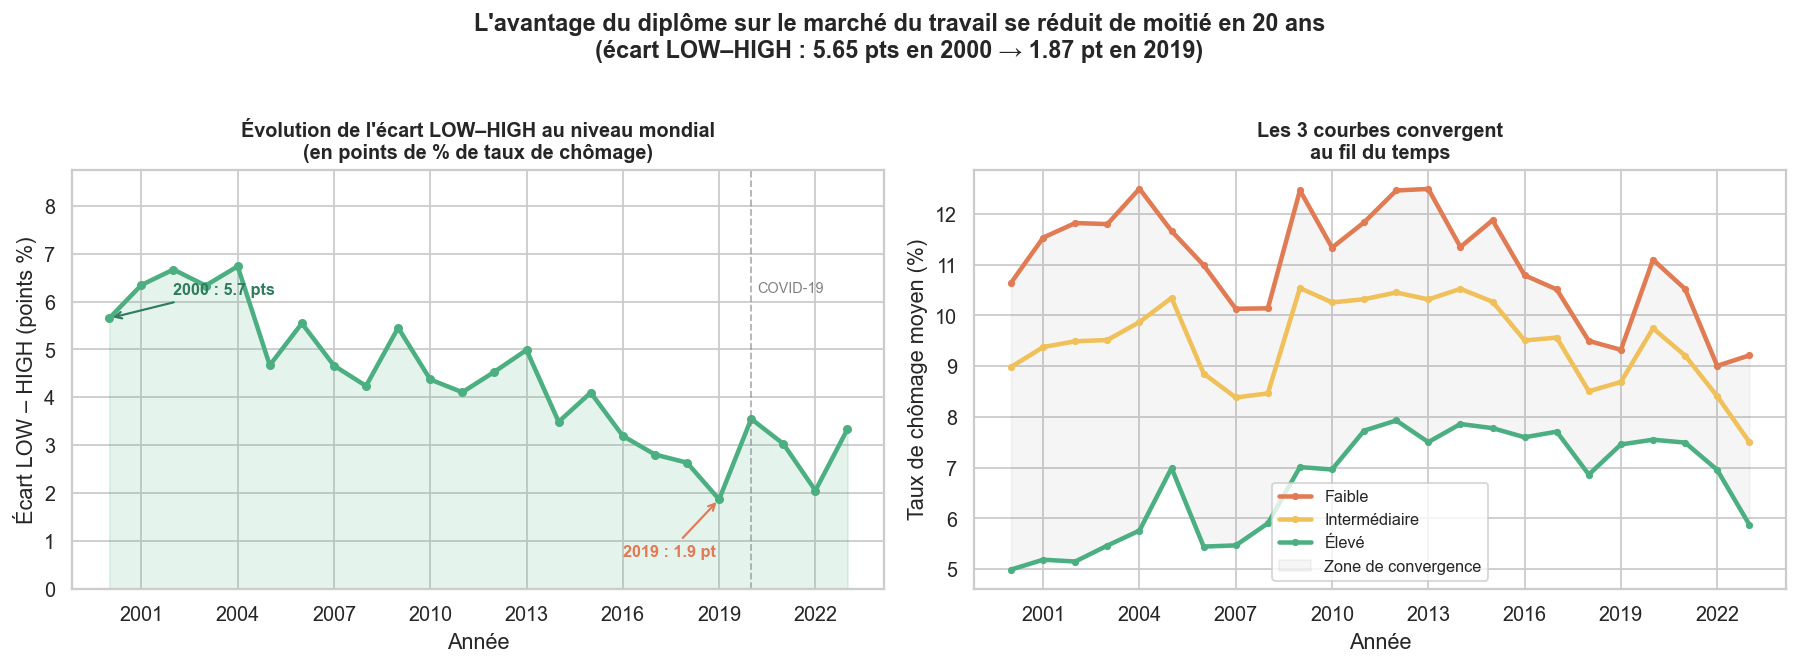

DESCRIPTION :
Évolution mondiale de l'écart LOW–HIGH entre 2000 et 2023.

CE QU'ON EN DÉDUIT :
L'avantage comparatif du diplôme s'érode : la massification du supérieur
réduit sa rareté et donc sa valeur différentielle sur le marché du travail.


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.plot(ecart_mondial.index, ecart_mondial['ecart'],
        color='#4caf82', linewidth=2.5, marker='o', markersize=4)
ax.fill_between(ecart_mondial.index, ecart_mondial['ecart'], alpha=0.15, color='#4caf82')
ax.annotate(f"2000 : {ecart_mondial.loc[2000,'ecart']:.1f} pts",
            xy=(2000, ecart_mondial.loc[2000,'ecart']),
            xytext=(2002, ecart_mondial.loc[2000,'ecart']+0.5),
            fontsize=9, fontweight='bold', color='#2e7d5e',
            arrowprops=dict(arrowstyle='->', color='#2e7d5e', lw=1.2))
ax.annotate(f"2019 : {ecart_mondial.loc[2019,'ecart']:.1f} pt",
            xy=(2019, ecart_mondial.loc[2019,'ecart']),
            xytext=(2016, ecart_mondial.loc[2019,'ecart']-1.2),
            fontsize=9, fontweight='bold', color='#e07b54',
            arrowprops=dict(arrowstyle='->', color='#e07b54', lw=1.2))
ax.axvline(2020, color='grey', linestyle='--', linewidth=1, alpha=0.6)
ax.text(2020.2, ecart_mondial['ecart'].max()*0.92, 'COVID-19', fontsize=8, color='grey')
ax.set_title('Évolution de l\'écart LOW–HIGH au niveau mondial\n(en points de % de taux de chômage)',
             fontweight='bold', fontsize=11)
ax.set_xlabel('Année'); ax.set_ylabel('Écart LOW – HIGH (points %)')
ax.set_ylim(0, ecart_mondial['ecart'].max()*1.3)
ax.xaxis.set_major_locator(mticker.MultipleLocator(3))

ax2 = axes[1]
for niv in NIVEAUX:
    ax2.plot(ecart_mondial.index, ecart_mondial[niv],
             label={'LOW':'Faible','MEDIUM':'Intermédiaire','HIGH':'Élevé'}[niv],
             color=COLORS[niv], linewidth=2.5, marker='o', markersize=3)
ax2.fill_between(ecart_mondial.index, ecart_mondial['LOW'], ecart_mondial['HIGH'],
                 alpha=0.08, color='grey', label='Zone de convergence')
ax2.set_title('Les 3 courbes convergent\nau fil du temps', fontweight='bold', fontsize=11)
ax2.set_xlabel('Année'); ax2.set_ylabel('Taux de chômage moyen (%)')
ax2.legend(fontsize=9); ax2.xaxis.set_major_locator(mticker.MultipleLocator(3))

plt.suptitle(
    'L\'avantage du diplôme sur le marché du travail se réduit de moitié en 20 ans\n'
    '(écart LOW–HIGH : 5.65 pts en 2000 → 1.87 pt en 2019)',
    fontsize=13, fontweight='bold', y=1.02
)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '15_convergence_ecart.png', bbox_inches='tight')
plt.show()

print('DESCRIPTION :')
print('Évolution mondiale de l\'écart LOW–HIGH entre 2000 et 2023.')
print()
print('CE QU\'ON EN DÉDUIT :')
print('L\'avantage comparatif du diplôme s\'érode : la massification du supérieur')
print('réduit sa rareté et donc sa valeur différentielle sur le marché du travail.')

---
## Figure 16 — Pologne –16 pts vs Suède +13 pts : trajectoires nationales opposées

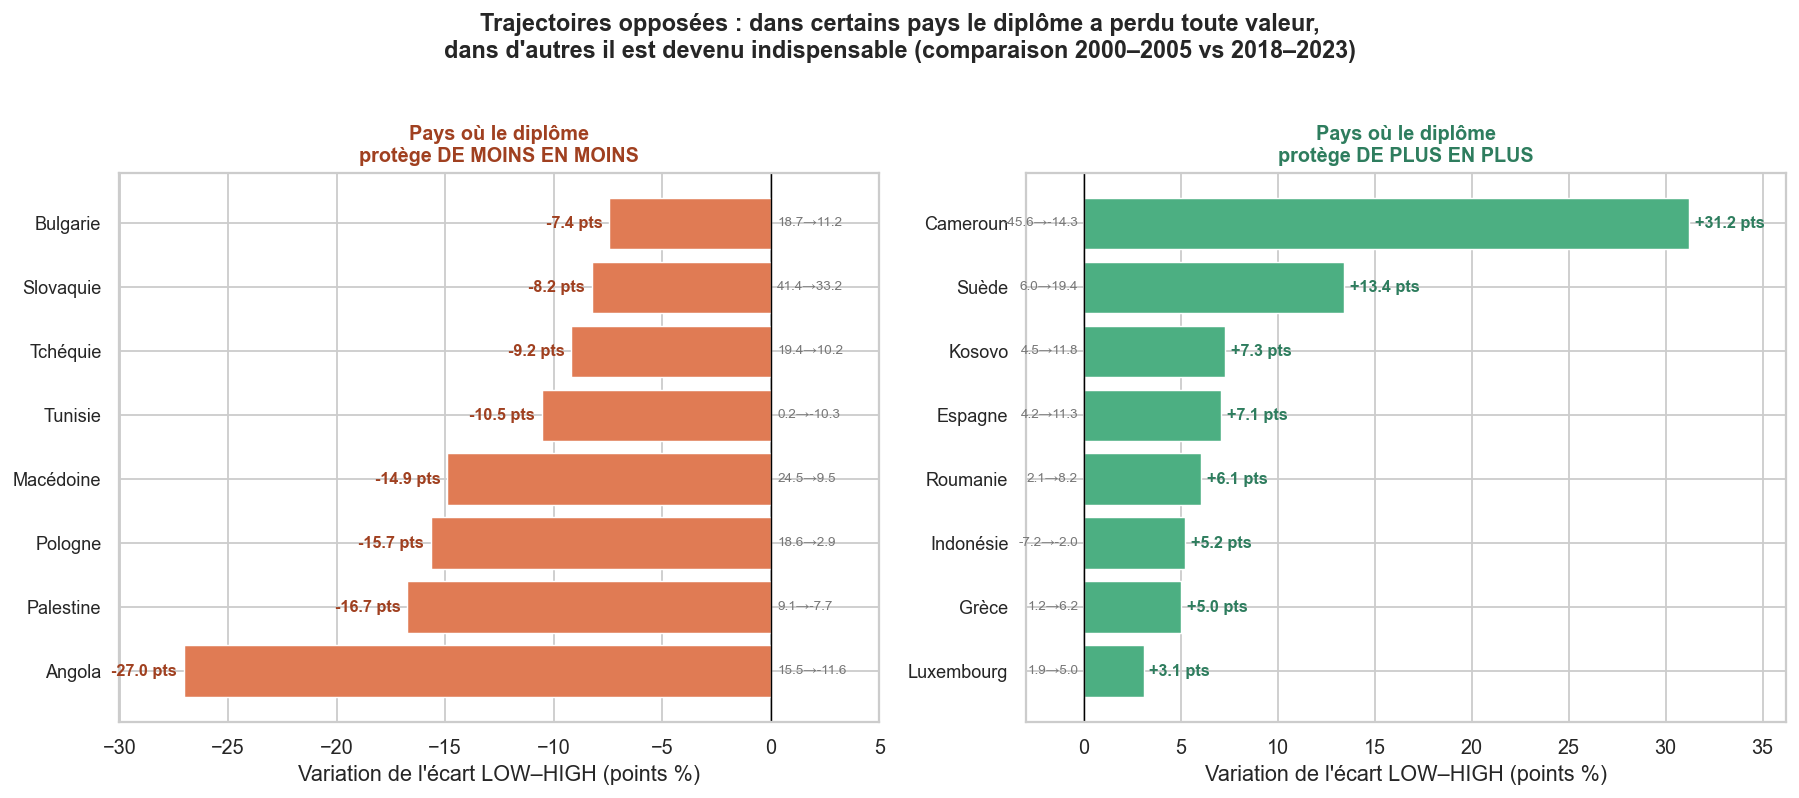

DESCRIPTION :
Variation de l'écart LOW–HIGH par pays entre 2000–2005 et 2018–2023.

CE QU'ON EN DÉDUIT :
La tendance mondiale à la convergence cache des trajectoires nationales opposées.
En Pologne : l'essor de l'emploi qualifié a réduit le chômage des peu diplômés
autant que celui des diplômés — effaçant l'écart.
En Suède : l'automatisation a exposé davantage les emplois peu qualifiés,
amplifiant la prime au diplôme.


In [28]:
debut_pays = pivot_temps[pivot_temps['time'] <= 2005].groupby('ref_area')['ecart'].mean()
fin_pays   = pivot_temps[pivot_temps['time'] >= 2018].groupby('ref_area')['ecart'].mean()
evol_pays  = (fin_pays - debut_pays).dropna()

perdants = evol_pays.sort_values().head(8)
gagnants = evol_pays.sort_values().tail(8)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ax = axes[0]
pays_p = [COUNTRY_NAMES.get(p, p) for p in perdants.index]
y_pos  = np.arange(len(perdants))
ax.barh(y_pos, perdants.values, color='#e07b54', edgecolor='white', linewidth=0.8)
ax.set_yticks(y_pos); ax.set_yticklabels(pays_p, fontsize=10)
ax.set_xlabel('Variation de l\'écart LOW–HIGH (points %)')
ax.set_title('Pays où le diplôme\nprotège DE MOINS EN MOINS',
             fontweight='bold', fontsize=11, color='#a04020')
ax.axvline(0, color='black', linewidth=0.8)
for i, v in enumerate(perdants.values):
    ax.text(v-0.3, i, f'{v:+.1f} pts', va='center', ha='right',
            fontsize=9, fontweight='bold', color='#a04020')
for i, pays in enumerate(perdants.index):
    d = debut_pays.get(pays, np.nan)
    f = fin_pays.get(pays, np.nan)
    if not np.isnan(d) and not np.isnan(f):
        ax.text(0.3, i, f'{d:.1f}→{f:.1f}', va='center', fontsize=7.5, color='#777')
ax.set_xlim(perdants.min()-3, 5)

ax2 = axes[1]
pays_g = [COUNTRY_NAMES.get(p, p) for p in gagnants.index]
y_pos2 = np.arange(len(gagnants))
ax2.barh(y_pos2, gagnants.values, color='#4caf82', edgecolor='white', linewidth=0.8)
ax2.set_yticks(y_pos2); ax2.set_yticklabels(pays_g, fontsize=10)
ax2.set_xlabel('Variation de l\'écart LOW–HIGH (points %)')
ax2.set_title('Pays où le diplôme\nprotège DE PLUS EN PLUS',
              fontweight='bold', fontsize=11, color='#2e7d5e')
ax2.axvline(0, color='black', linewidth=0.8)
for i, v in enumerate(gagnants.values):
    ax2.text(v+0.3, i, f'{v:+.1f} pts', va='center',
             fontsize=9, fontweight='bold', color='#2e7d5e')
for i, pays in enumerate(gagnants.index):
    d = debut_pays.get(pays, np.nan)
    f = fin_pays.get(pays, np.nan)
    if not np.isnan(d) and not np.isnan(f):
        ax2.text(-0.3, i, f'{d:.1f}→{f:.1f}', va='center', ha='right',
                 fontsize=7.5, color='#777')
ax2.set_xlim(-3, gagnants.max()+5)

plt.suptitle(
    'Trajectoires opposées : dans certains pays le diplôme a perdu toute valeur,\n'
    'dans d\'autres il est devenu indispensable (comparaison 2000–2005 vs 2018–2023)',
    fontsize=13, fontweight='bold', y=1.02
)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '16_pays_divergents.png', bbox_inches='tight')
plt.show()

print('DESCRIPTION :')
print('Variation de l\'écart LOW–HIGH par pays entre 2000–2005 et 2018–2023.')
print()
print('CE QU\'ON EN DÉDUIT :')
print('La tendance mondiale à la convergence cache des trajectoires nationales opposées.')
print('En Pologne : l\'essor de l\'emploi qualifié a réduit le chômage des peu diplômés')
print('autant que celui des diplômés — effaçant l\'écart.')
print('En Suède : l\'automatisation a exposé davantage les emplois peu qualifiés,')
print('amplifiant la prime au diplôme.')